In [30]:
import pandas as pd

def charger(fichier, colonne_date):
    df = pd.read_csv(fichier, index_col=colonne_date)
    df.index = pd.to_datetime(df.index, utc=True)
    return df.sort_index()

df_data = charger("eco2mix_15min.csv", "date_heure")
df_price = charger("prix_day_ahead_fr.csv", "dates")

df_meteo = charger("meteo_horaire_paris.csv", "time")
# Vérifie qu'il n'y a pas d'heure en double avant de rééchantillonner
assert not df_meteo.index.duplicated().any(), "doublons d'horodatage dans la météo"

df_meteo_15 = (
    df_meteo
    .resample("15min")
    .asfreq()                    # crée les quarts d'heure, vides pour l'instant
    .interpolate(method="time")  # remplit selon la distance temporelle réelle
)

df_total1 = pd.merge(
    df_data,
    df_price,
    left_index=True,
    right_index=True,
    how="left",
)

df_total2 = pd.merge(
    df_total1,
    df_meteo_15,
    left_index=True,
    right_index=True,
    how="left",
)

debut = pd.Timestamp("2015-08-01", tz="Europe/Paris").tz_convert("UTC")
fin = pd.Timestamp("2026-09-01", tz="Europe/Paris").tz_convert("UTC")

df_total = df_total2.loc[debut:fin]

# print(df_total["solaire"].head(10))


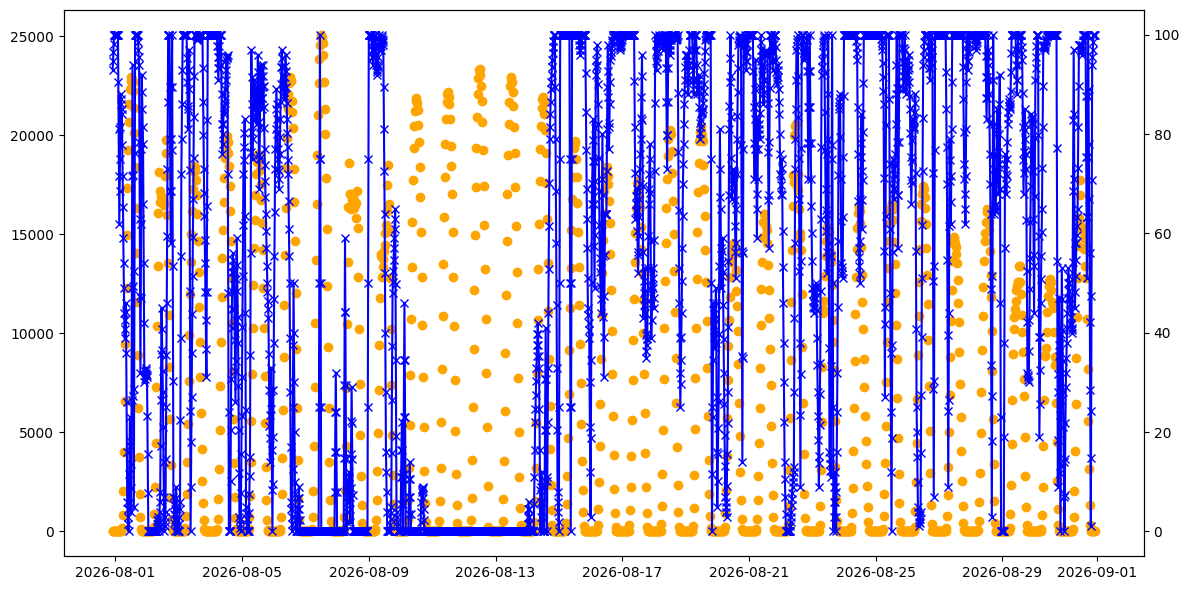

In [25]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6), sharex=True)

ax.plot(df_total.index, df_total["solaire"], label="Solaire", color="orange", marker="o")
axbis = ax.twinx()
axbis.plot(df_total.index, df_total["cloud_cover"], label="Couverture nuageuse", color="blue", marker="x")

plt.tight_layout()
plt.show()

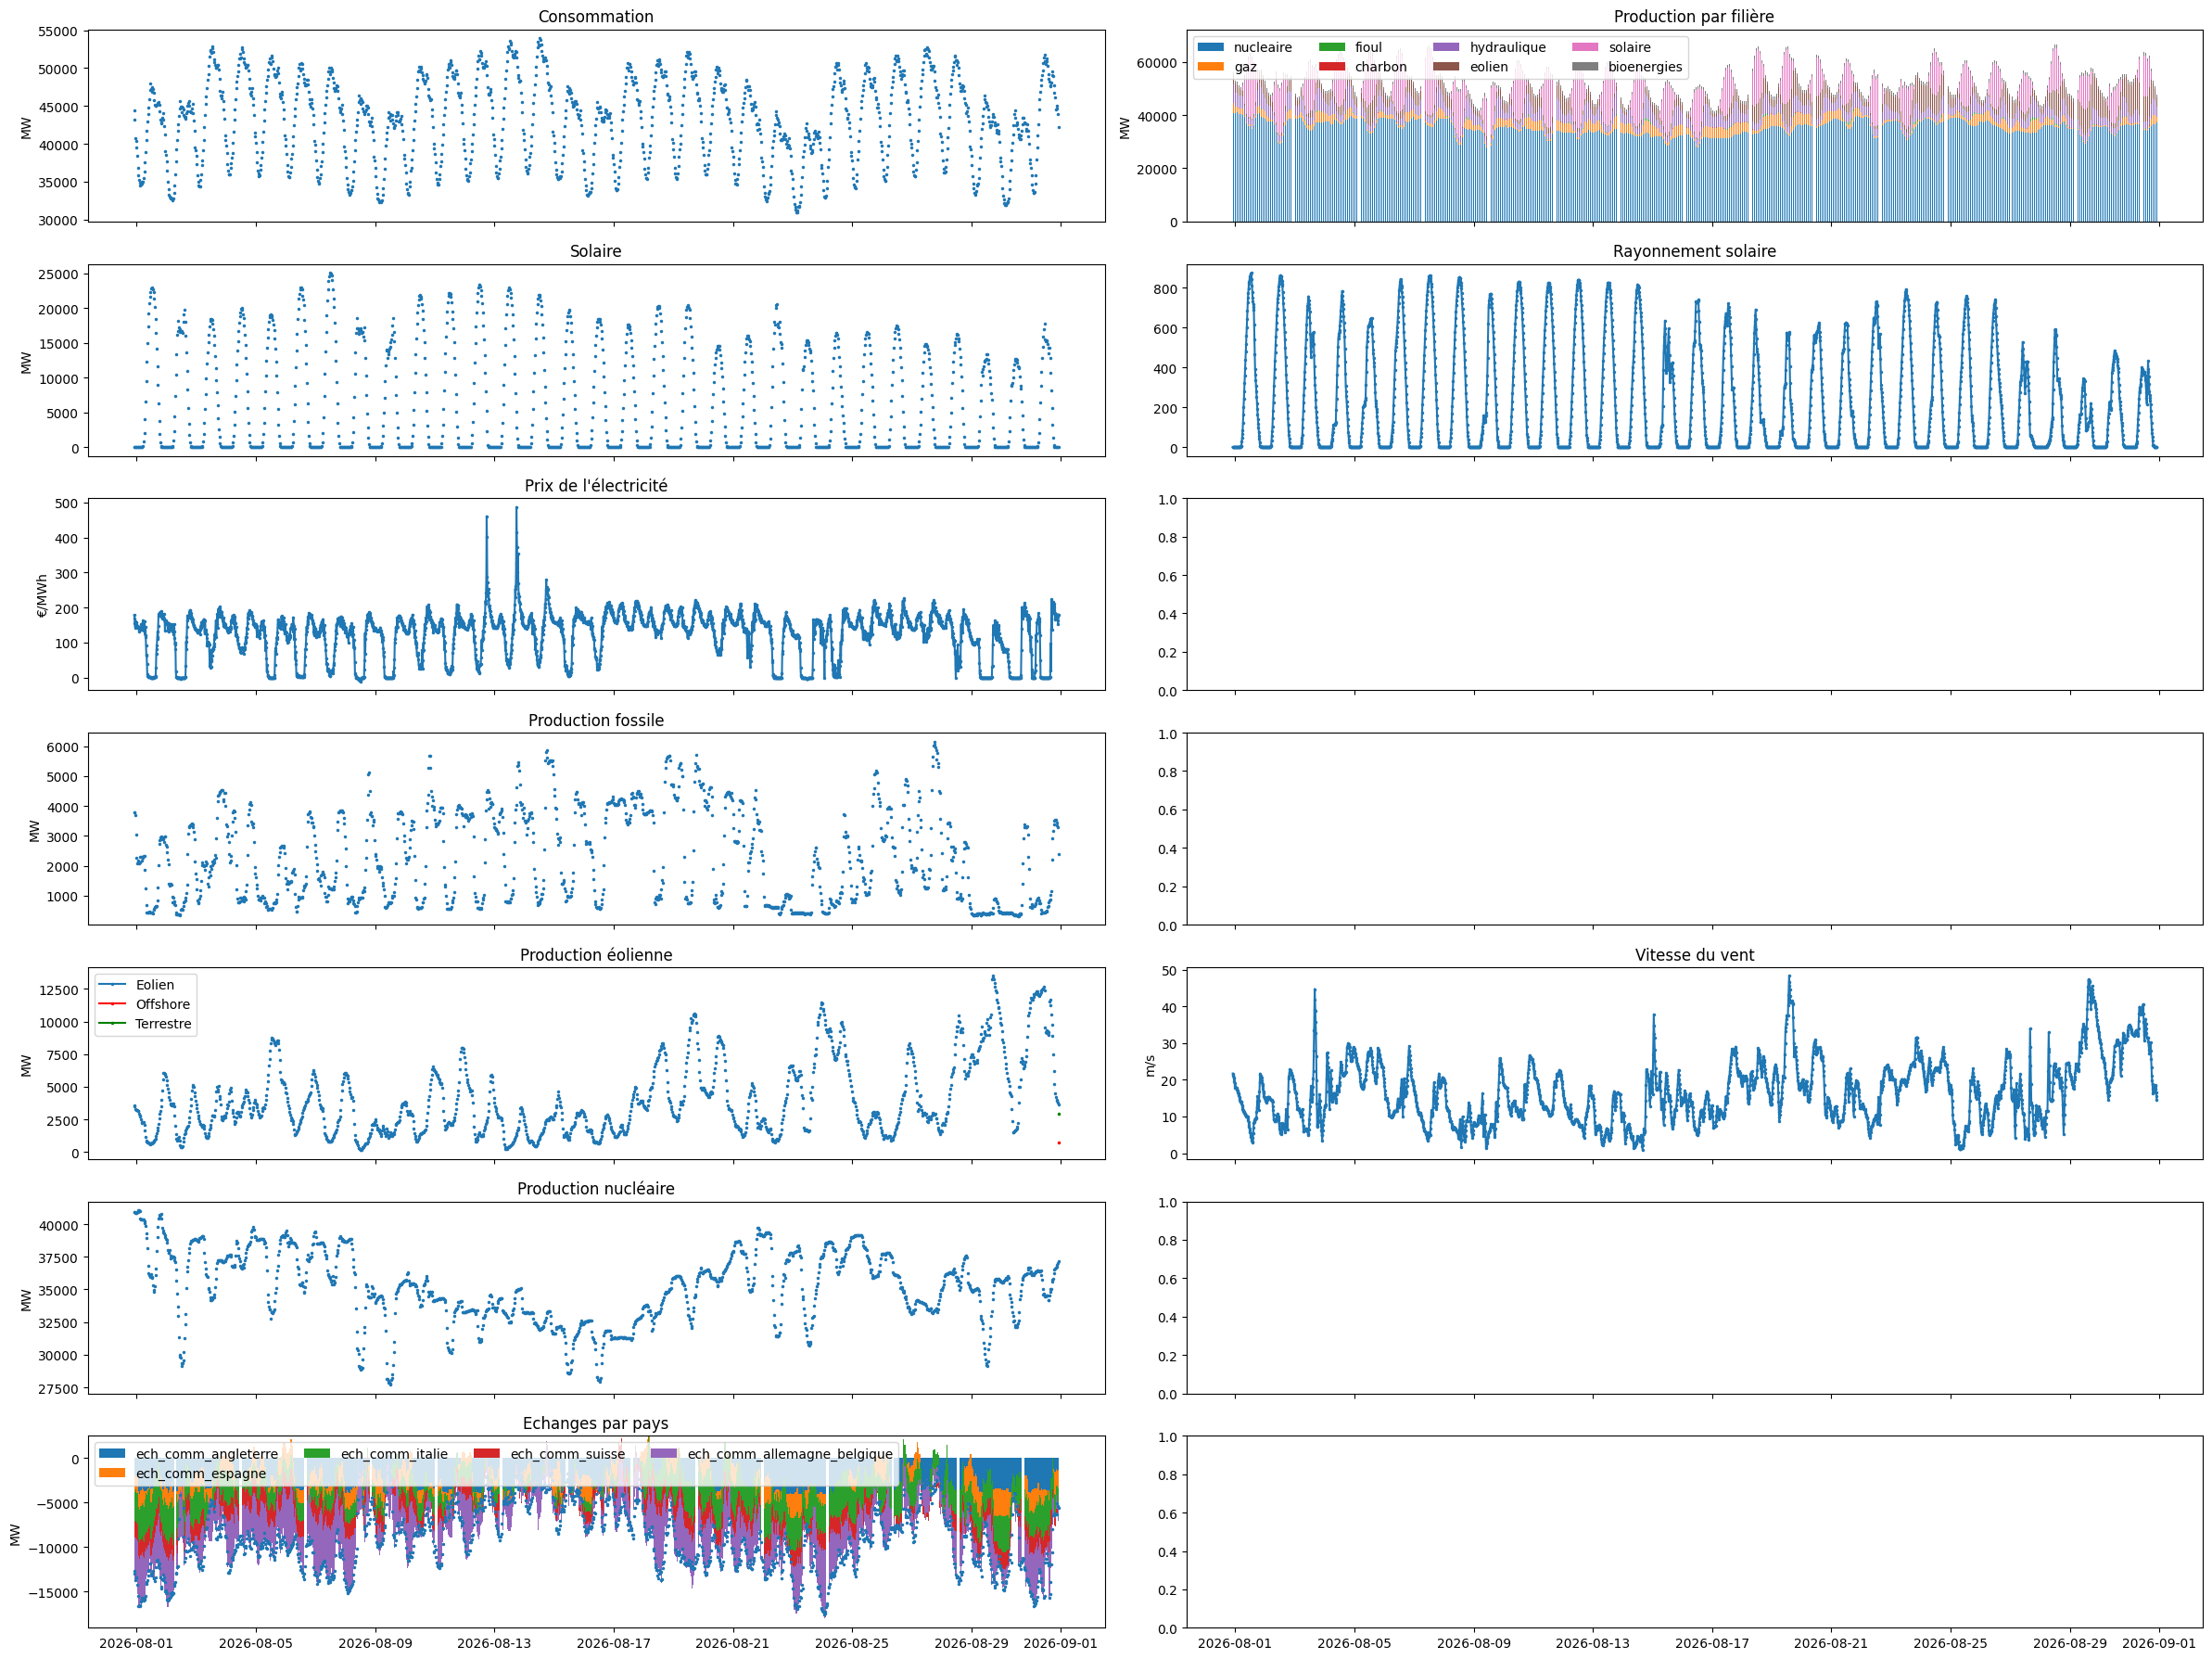

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(7, 2, figsize=(24, 18), sharex=True)

ax[0][0].plot(df_total.index, df_total["consommation"], marker=".", markersize=3)
ax[0][0].set_title("Consommation")
ax[0][0].set_ylabel("MW")

# Graphique en haut à droite : production par filière
prod = ['nucleaire', 'gaz', 'fioul', 'charbon', 'hydraulique',
        'eolien', 'solaire', 'bioenergies']

bottom = None
for f in prod:
    valeurs = df_total[f].fillna(0)
    ax[0][1].bar(df_total.index, valeurs, width=0.01, bottom=bottom, label=f)
    bottom = valeurs if bottom is None else bottom + valeurs

ax[0][1].set_title("Production par filière")
ax[0][1].set_ylabel("MW")
ax[0][1].legend(loc="upper left", ncol=4)

ax[1][0].plot(df_total.index, df_total["solaire"], marker=".", markersize=3)
ax[1][0].set_title("Solaire")
ax[1][0].set_ylabel("MW")

ax[2][0].plot(df_total.index, df_total["price"], marker=".", markersize=3)
ax[2][0].set_title("Prix de l'électricité")
ax[2][0].set_ylabel("€/MWh")

ax[3][0].plot(df_total.index, df_total["fioul"] + df_total["charbon"] + df_total["gaz"],
              marker=".", markersize=3)
ax[3][0].set_title("Production fossile")
ax[3][0].set_ylabel("MW")

ax[4][0].plot(df_total.index, df_total["eolien"], marker=".", markersize=3, label="Eolien")
ax[4][0].plot(df_total.index, df_total["eolien_offshore"], color="red", marker=".", markersize=3, label="Offshore")
ax[4][0].plot(df_total.index, df_total["eolien_terrestre"], color="green", marker=".", markersize=3, label="Terrestre")
ax[4][0].set_title("Production éolienne")
ax[4][0].set_ylabel("MW")
ax[4][0].legend(loc="upper left")

ax[5][0].plot(df_total.index, df_total["nucleaire"], marker=".", markersize=3)
ax[5][0].set_title("Production nucléaire")
ax[5][0].set_ylabel("MW")

ax[4][1].plot(df_total.index, df_total["wind_speed_100m"], marker=".", markersize=3)
ax[4][1].set_title("Vitesse du vent")
ax[4][1].set_ylabel("m/s")

ax[1][1].plot(df_total.index, df_total["shortwave_radiation"], marker=".", markersize=3)
ax[1][1].set_title("Rayonnement solaire")

ax[6][0].plot(df_total.index, df_total["ech_physiques"], marker=".", markersize=3)
ax[6][0].set_title("Echanges physiques")

echanges = ['ech_comm_angleterre', 'ech_comm_espagne', 'ech_comm_italie',
            'ech_comm_suisse', 'ech_comm_allemagne_belgique']

bottom = None
for f in echanges:
    ax[6][0].bar(df_total.index, df_total[f], width=0.01, bottom=bottom, label=f)
    bottom = df_total[f] if bottom is None else bottom + df_total[f]

ax[6][0].set_ylabel("MW")
ax[6][0].set_title("Echanges par pays")
ax[6][0].legend(loc="upper left", ncol=4)

plt.tight_layout()
plt.show()

In [13]:
midi = pd.Timestamp("2026-08-31 12:00", tz="Europe/Paris").tz_convert("UTC")
print(df_total.loc[midi, "solaire"])

15830.0


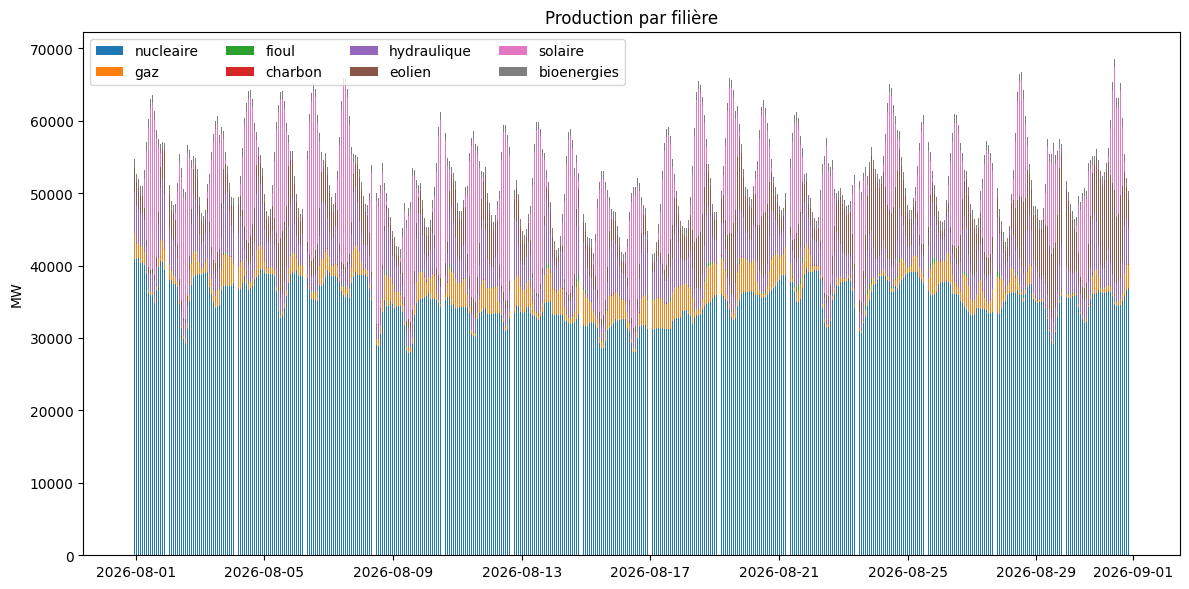

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6), sharex=True)

# Graphique en haut à droite : production par filière
prod = ['nucleaire', 'gaz', 'fioul', 'charbon', 'hydraulique',
        'eolien', 'solaire', 'bioenergies']

bottom = None
for f in prod:
    valeurs = df_total[f].fillna(0)
    ax.bar(df_total.index, valeurs, width=0.01, bottom=bottom, label=f)
    bottom = valeurs if bottom is None else bottom + valeurs

ax.set_title("Production par filière")
ax.set_ylabel("MW")
ax.legend(loc="upper left", ncol=4)

plt.tight_layout()
plt.show()

In [9]:
def empiler_avec_signe(ax, index, colonnes, df):
    cumul_pos = None
    cumul_neg = None

    for f in colonnes:
        valeurs = df[f].fillna(0)
        positif = valeurs.clip(lower=0)  # garde le positif, met le reste à 0
        negatif = valeurs.clip(upper=0)  # garde le négatif, met le reste à 0

        ax.bar(index, positif, width=0.01, bottom=cumul_pos, label=f)
        cumul_pos = positif if cumul_pos is None else cumul_pos + positif

        ax.bar(index, negatif, width=0.01, bottom=cumul_neg, label="_nolegend_")
        cumul_neg = negatif if cumul_neg is None else cumul_neg + negatif

    ax.axhline(0, color="black", linewidth=0.8)
    ax.legend(loc="upper left", ncol=4)

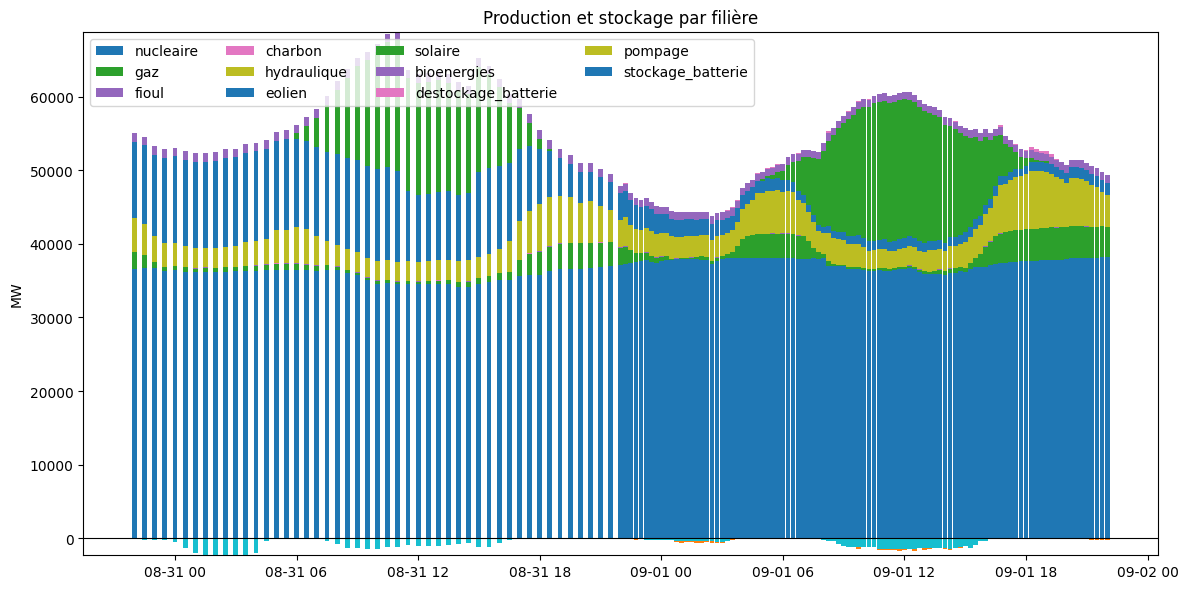

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6), sharex=True)
prod = ['nucleaire', 'gaz', 'fioul', 'charbon', 'hydraulique',
        'eolien', 'solaire', 'bioenergies', 'destockage_batterie',
        'pompage', 'stockage_batterie']

empiler_avec_signe(ax, df_total.index, prod, df_total)
ax.set_title("Production et stockage par filière")
ax.set_ylabel("MW")

plt.tight_layout()
plt.show()

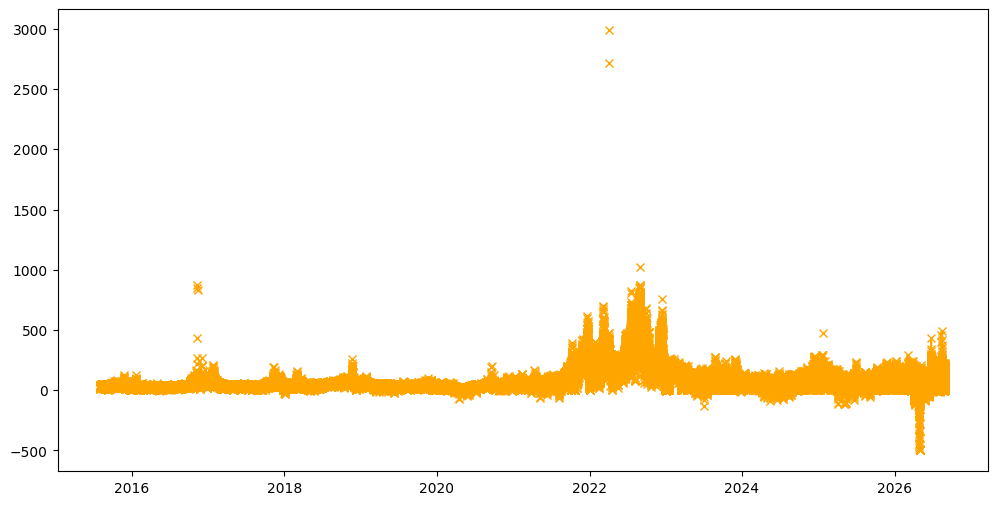

In [33]:
fig, ax = plt.subplots(1, 1, figsize=(12, 6), sharex=True)

ax.plot(df_total.index, df_total["price"], label="Prix", color="orange", marker="x", linestyle="-")